In [32]:
import PyMPDATA
import numpy as np
import matplotlib.pyplot as plt
from PyMPDATA import ScalarField, VectorField, Options, Stepper, Solver, boundary_conditions

print(PyMPDATA.__file__)

c:\Users\micha\AppData\Local\Programs\Python\Python314\Lib\site-packages\PyMPDATA\__init__.py


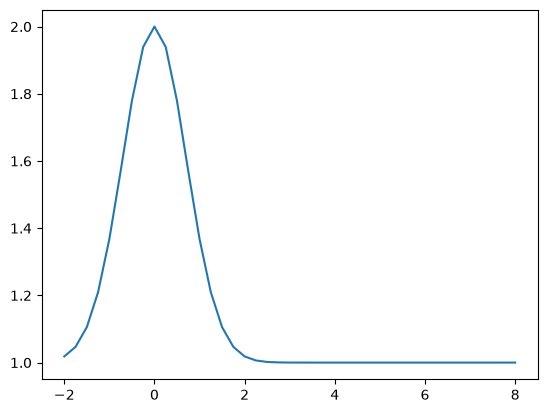

In [33]:
x = np.linspace(-2, 8, 41)
y = np.exp(-x**2) + 1

plt.figure()
plt.plot(x, y)
plt.show()

In [34]:
common = {
    'halo' : ( options := Options(nonoscillatory=True) ).n_halo,
    'boundary_conditions' : ( boundary_conditions.Periodic(), ) 
}
advector = VectorField(**common, data=(np.full(x.size + 1, 1/4),))
advectee = ScalarField(**common, data=y)
solver = Solver(advectee=advectee, advector=advector, stepper=Stepper(n_dims=1, options=options))
solver.advance(n_steps=100)

13501.0

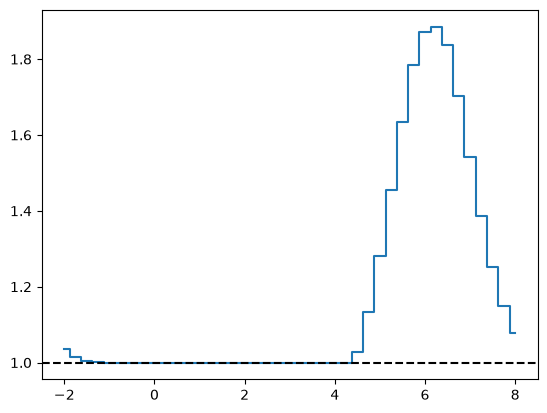

In [35]:
plt.figure()
plt.step(x, solver.advectee.get(), where='mid')
plt.axhline(1, linestyle='--', color='k')
plt.show()